<a href="https://colab.research.google.com/github/ismailkirac/dis-sagligi-sporcu-performansi/blob/main/Hafta6_Colab_CSV_JSON_Drive_Ekip_Sinif_ipynb_adl%C4%B1_not_defterinin_kopyas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Hafta | Google Colab, CSV/JSON, Grafikler ve Ekip Çalışması

**Yazılım Mühendisliği Temelleri — 2026 Güz**

Bu uygulamada Python ile temel işlemleri, dosya biçimlerini, tablo okumayı, grafik üretmeyi, dosya kaydetmeyi, Drive ve GitHub iş akışını öğreneceğiz.

> Bu defterin örnek verileri **temsili/öğretim amaçlıdır**, ölçüm veya bilimsel araştırma sonucu değildir.

## Başlamadan önce
1. [Google Colab](https://colab.research.google.com/) adresinde not defterini açın.
2. **Dosya → Drive’da kopya kaydet** ile kendi kopyanızı oluşturun.
3. Kod hücresini **Shift+Enter** ile çalıştırın.
4. Hücreleri sırayla yürütün.
5. Opsiyonel Drive ve dosya yükleme hücrelerini yalnızca anlatımdan sonra etkinleştirin.

**Notebook (.ipynb)**; açıklama, kod ve çıktı içeren bir dosyadır. **CSV** satır–sütun, **JSON** yapılandırılmış veri içindir.

## 1. İlk Python komutları: metin ve dört işlem

In [19]:
print("Merhaba Colab!")
print("Toplam:", 5+7)
print("Bölme:", 12/5)

Merhaba Colab!
Toplam: 12
Bölme: 2.4


## 2. Değişken, liste ve basit istatistik
Bir değişken değeri saklar. Liste birden fazla değeri sıralı tutar. `sum`, `len`, `min`, `max` Python’ın yerleşik işlevleridir.

In [20]:
saatler = [2, 3, 1, 4, 2]
print("Toplam:", sum(saatler))
print("Ortalama:", sum(saatler)/len(saatler))
print("Min:", min(saatler), "Maks:", max(saatler))

Toplam: 12
Ortalama: 2.4
Min: 1 Maks: 4


## 3. CSV ve JSON: aynı veriyi iki dosyaya kaydetme
Bu hücre, örnek veri dosyalarını Colab’ın **geçici çalışma klasöründe** oluşturur. İsterseniz öğretmenin verdiği `ornek_proje_verisi.csv` ve `.json` dosyalarını ayrıca indirip **Dosyalar → Yükle** üzerinden de deneyebilirsiniz.

In [21]:
from pathlib import Path
import pandas as pd

kayitlar = [{'gun': 'Pazartesi', 'faaliyet': 'Gereksinimler', 'calisma_saati': 2, 'tamamlanan_gorev': 1}, {'gun': 'Salı', 'faaliyet': 'Tasarım', 'calisma_saati': 3, 'tamamlanan_gorev': 2}, {'gun': 'Çarşamba', 'faaliyet': 'UML', 'calisma_saati': 1, 'tamamlanan_gorev': 1}, {'gun': 'Perşembe', 'faaliyet': 'Uygulama', 'calisma_saati': 5, 'tamamlanan_gorev': 3}, {'gun': 'Cuma', 'faaliyet': 'Test', 'calisma_saati': 2, 'tamamlanan_gorev': 2}]

veri = pd.DataFrame(kayitlar)
veri.to_csv("ornek_proje_verisi.csv", index=False, encoding="utf-8-sig")
veri.to_json("ornek_proje_verisi.json", orient="records", force_ascii=False, indent=2)
print("Oluşturulan örnek dosyalar:", Path("ornek_proje_verisi.csv").name, "ve", Path("ornek_proje_verisi.json").name)

Oluşturulan örnek dosyalar: ornek_proje_verisi.csv ve ornek_proje_verisi.json


### Manuel yükleme — yalnızca Google Colab’da istenirse
Bilgisayarınızdaki CSV/JSON’u yüklemek için soldaki **Dosyalar (Files)** panelindeki yükleme düğmesini kullanabilirsiniz. Alternatif olarak aşağıdaki hücrede `YUKLE = True` yapabilirsiniz.

**Uyarı:** `Çalışma zamanı → Tümünü çalıştır` komutu yükleme penceresinde beklemesin diye varsayılanı `False`.

In [22]:
YUKLE = False  # Öğretmen yönlendirdiğinde True yapın.
if YUKLE:
    from google.colab import files
    yuklenen_dosyalar = files.upload()
    print("Yüklenen dosyalar:", list(yuklenen_dosyalar))
else:
    print("Manuel yükleme atlandı; örnek dosyalar hazır.")

Manuel yükleme atlandı; örnek dosyalar hazır.


## 4. CSV dosyasını pandas ile oku
`DataFrame` satır ve sütunlardan oluşan tablodur. `head()` ilk satırları, `shape` tablo boyutunu gösterir.

In [23]:
csv_tablo = pd.read_csv("ornek_proje_verisi.csv")
print("Tablonun boyutu (satır, sütun):", csv_tablo.shape)
print(csv_tablo.head())

Tablonun boyutu (satır, sütun): (5, 4)
         gun       faaliyet  calisma_saati  tamamlanan_gorev
0  Pazartesi  Gereksinimler              2                 1
1       Salı        Tasarım              3                 2
2   Çarşamba            UML              1                 1
3   Perşembe       Uygulama              5                 3
4       Cuma           Test              2                 2


## 5. Veriyi incele ve özetle
`isna().sum()` eksik değerleri sayar. Sayısal sütunları toplam ve ortalama için kullanabiliriz.

**Birimleri belirtin:** Saat ile görev sayısı farklı ölçülerdir.

In [24]:
print("Sütunlar:", list(csv_tablo.columns))
print("Eksik kayıt sayıları: ", csv_tablo.isna().sum())
print("Toplam çalışma saati:", csv_tablo["calisma_saati"].sum())
print("Ortalama çalışma saati:", csv_tablo["calisma_saati"].mean())
print("Tamamlanan görev toplamı:", csv_tablo["tamamlanan_gorev"].sum())

Sütunlar: ['gun', 'faaliyet', 'calisma_saati', 'tamamlanan_gorev']
Eksik kayıt sayıları:  gun                 0
faaliyet            0
calisma_saati       0
tamamlanan_gorev    0
dtype: int64
Toplam çalışma saati: 13
Ortalama çalışma saati: 2.6
Tamamlanan görev toplamı: 9


## 6. JSON dosyasını oku
`read_json`, liste biçimindeki JSON kayıtlarını da pandas tablosuna dönüştürür. Bu örnekte CSV ve JSON aynı temsili veriyi içerir.

In [25]:
json_tablo = pd.read_json("ornek_proje_verisi.json")
print(json_tablo.head(2))
print("CSV ve JSON aynı satır sayısına sahip mi?", len(csv_tablo)==len(json_tablo))

         gun       faaliyet  calisma_saati  tamamlanan_gorev
0  Pazartesi  Gereksinimler              2                 1
1       Salı        Tasarım              3                 2
CSV ve JSON aynı satır sayısına sahip mi? True


### İsteğe bağlı: İnternetteki gerçek bir CSV dosyasını okumak
Bu dersin temsili örneğinden ayrı olarak, [UCI Iris veri seti](https://archive.ics.uci.edu/dataset/53/iris) hakkında bilgi edinebilirsiniz. Aşağıdaki internet adresi herkese açık bir CSV kopyasıdır. `UZAK_VERI_OKU = True` yaptığınızda Colab internet üzerinden dosyayı okur. Bu aşama **zorunlu değildir**; sınıftaki esas etkinlik öğretmenin verdiği CSV ve JSON ile yapılır. Kaynağın adını, sürümünü ve kullanım şartlarını raporda belirtin.

In [26]:
UZAK_VERI_OKU = False  # İnternet varsa ve öğretmen söylerse True yapın.
if UZAK_VERI_OKU:
    iris_csv_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
    iris = pd.read_csv(iris_csv_url)
    print("Iris veri seti:", iris.shape)
    print(iris.head())
else:
    print("Uzak CSV örneği atlandı; yerel örnek verilerle devam edin.")

Uzak CSV örneği atlandı; yerel örnek verilerle devam edin.


## 7. Matplotlib ile sütun ve çizgi grafikleri
- **Sütun:** Günlere ait değerleri karşılaştırır.
- **Çizgi:** Zaman sırasına göre değişimi gösterir.
- Grafikler betimleyicidir; tek başına neden-sonuç ilişkisi kanıtlamaz.

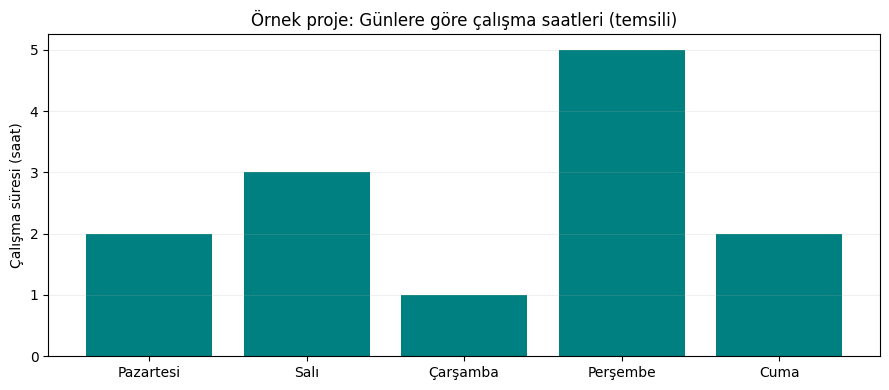

In [27]:
import matplotlib.pyplot as plt
from pathlib import Path

cikti = Path("sonuclar")
cikti.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(csv_tablo["gun"], csv_tablo["calisma_saati"], color="teal")
ax.set_title("Örnek proje: Günlere göre çalışma saatleri (temsili)")
ax.set_ylabel("Çalışma süresi (saat)")
ax.grid(axis="y",alpha=.18)
fig.tight_layout()
fig.savefig(cikti/"calisma_saatleri.png", dpi=160)
plt.show()

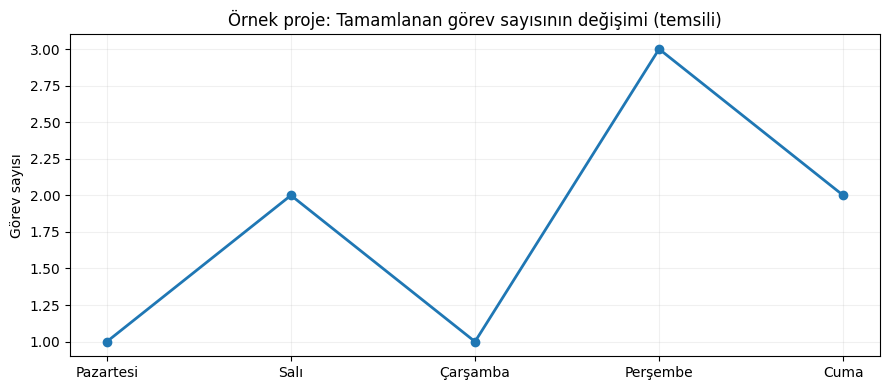

In [28]:
fig2, ax2 = plt.subplots(figsize=(9,4))
ax2.plot(csv_tablo["gun"], csv_tablo["tamamlanan_gorev"], marker="o", linewidth=2)
ax2.set_title("Örnek proje: Tamamlanan görev sayısının değişimi (temsili)")
ax2.set_ylabel("Görev sayısı")
ax2.grid(alpha=.18)
fig2.tight_layout()
fig2.savefig(cikti/"gorev_degisimi.png", dpi=160)
plt.show()

## 8. Sonuçları CSV, JSON ve PNG olarak saklama
Not defterini Drive’a kaydetmek, **çalışma ortamının bütün geçici dosyalarını otomatik olarak saklamak değildir**. Önce sonuç dosyalarını oluşturuyoruz.

In [29]:
ozet = pd.DataFrame([{"metrik":"Toplam çalışma saati", "deger":csv_tablo["calisma_saati"].sum()},
                      {"metrik":"Ortalama çalışma saati", "deger":csv_tablo["calisma_saati"].mean()},
                      {"metrik":"Toplam tamamlanan görev", "deger":csv_tablo["tamamlanan_gorev"].sum()}])
ozet.to_csv(cikti/"ozet.csv", index=False, encoding="utf-8-sig")
ozet.to_json(cikti/"ozet.json", orient="records", indent=2, force_ascii=False)
print("Oluşan dosyalar:", sorted(p.name for p in cikti.iterdir()))

Oluşan dosyalar: ['calisma_saatleri.png', 'gorev_degisimi.png', 'ozet.csv', 'ozet.json']


### Sonuç dosyalarını indirme
İsterseniz sol taraftaki Dosyalar panelinden `sonuclar` klasörüne gidip dosyaları tek tek indirebilirsiniz. Alternatif olarak kod ile ZIP oluşturun:

In [30]:
import shutil
zip_yolu = shutil.make_archive("hafta6_sonuclar", "zip", "sonuclar")
print("İndirilebilir ZIP:", zip_yolu)

İndirilebilir ZIP: /content/hafta6_sonuclar.zip


## 9. Google Drive’a kaydetme (isteğe bağlı)
**Notebook için:** Dosya → Drive’da kopya kaydet.

**Python ile veri dosyalarını Drive’a yazmak için:** aşağıdaki `DRIVE_BAGLA = True` seçeneğini yalnızca **Google Colab** içinde ve izinleri okuyarak açın. Bu örneği sınıfta öğretmeninizle birlikte yapın.

> Paylaştığınız notebook, Drive erişiminizi otomatik olarak başkasına vermez; her kullanıcı kendi izinlerini yönetir.

In [31]:
DRIVE_BAGLA = False  # Colab ortamında ve bilinçli izinle True yapın
if DRIVE_BAGLA:
    from google.colab import drive
    drive.mount("/content/drive")
    hedef = Path("/content/drive/MyDrive/Hafta6_Colab_Sonuclar")
    hedef.mkdir(parents=True, exist_ok=True)
    for dosya in cikti.iterdir():
        shutil.copy2(dosya, hedef/dosya.name)
    print("Drive çıktıları:", list(hedef.iterdir()))
else:
    print("Drive bağlama atlandı; dosyalar Colab çalışma klasöründe hazır.")

Drive bağlama atlandı; dosyalar Colab çalışma klasöründe hazır.


## 10. CPU – GPU – TPU
**CPU** genel amaçlı işlemci, **GPU** paralel hesaplama hızlandırıcısı, **TPU** bazı makine öğrenmesi işlemlerine özel hızlandırıcıdır.

Bu dersin tablosu ve grafikleri için **CPU yeterlidir**. GPU/TPU ücretsiz planda her zaman sağlanmaz ve seçili GPU’nun kullanılması için kodun bunu desteklemesi gerekir.

In [32]:
import platform
print("Python:", platform.python_version())
print("Bu örneğin çalışması için GPU gerekli değildir.")

Python: 3.13.18
Bu örneğin çalışması için GPU gerekli değildir.


## 11. Ekip çalışması: paylaşım ve GitHub
**Paylaş düğmesi:** görüntüleme, yorum yapma ve düzenleme izinlerini yönetir.

**Dikkat:** Notebook paylaşılır, fakat herkesin kendi çalışma zamanı, geçici dosyaları ve özel Drive izinleri ayrı olabilir. Aynı hücreyi aynı anda düzenlerken anlaşmazlık olabilir.

**GitHub:** Dosya → GitHub’a kopya kaydet (arayüz/izin gerekebilir) veya `.ipynb` indirip repoya yükleyin. README.md içinde veri kaynağı, görev dağılımı ve sonuç özeti yazın. Kişisel veriyi herkese açık repoya yüklemeyin.

## 12. Sınıf etkinliği ve değerlendirme
1. 3. bölümdeki `kayitlar` listesinde bir `calisma_saati` değerini değiştirin; ardından hücreleri baştan çalıştırın.
2. Tekrar okuyup toplam/ortalamayı hesaplayın.
3. Sütun grafiğini yeniden üretin.
4. `.png` ve `.csv` çıktısını kaydedin.
5. En az **4 cümleyle** açıklayın: Veri kaynağı, ölçü birimi, temel bulgu, sınırlılık.
6. Görev paylaşımını Markdown hücresine yazın ve Github’a gönderin.

**Önemli:** Veriler temsili ise bunu açıkça belirtin.

### Hafta 6 Sınıf Etkinliği Değerlendirme Raporu

- **Veri Kaynağı:** Bu çalışmada kullanılan proje takip kayıtları, 2026 Güz Yazılım Mühendisliği Temelleri dersi kapsamında eğitim amacıyla oluşturulmuş temsili bir veri setidir.
- **Ölçü Birimleri:** Proje faaliyet süreleri saat cinsinden, tamamlanan işler ise adet (görev sayısı) olarak ölçülmüştür.
- **Temel Bulgu:** Perşembe gününün çalışma saati 5 olarak güncellendiğinde haftalık toplam çalışma süresi 13 saate, günlük ortalama çalışma süresi ise 2.6 saate yükselmiştir; en yüksek efor ve iş çıktısı perşembe gününde gerçekleşmiştir.
- **Sınırlılık:** Veriler tek bir haftalık temsili sprinti kapsamakta olup görevlerin zorluk derecesini ve ekibin uzun vadeli hızını (velocity) yansıtmamaktadır.

#### Ekip Görev Dağılımı
- **İsmail Kıraç :** CSV ve JSON veri işleme, Pandas özet istatistik hesaplamaları.
- **İsmail Kıraç :** Matplotlib görselleştirmeleri, dosya dışa aktarma (ZIP) ve değerlendirme raporunun hazırlanması.